# Phase 4 — BERT fine-tuning and grounded document QA

This notebook reviews the completed compact-BERT classifier and local RAG assistant. It reads recorded results and demonstrates source-quoted QA; it does not retrain the classifier. Run `python -m medical_doc_assistant phase4` first.

The evaluated path is English medicine-label text. As required by the plan, the project is informational only and is not medical advice.

In [1]:
import json
from pathlib import Path
import pandas as pd
import torch
from IPython.display import Image, display
from medical_doc_assistant.bert_model import classify_bert_text, load_bert_checkpoint, wordpiece_windows
from medical_doc_assistant.document_index import DocumentIndex
from medical_doc_assistant.grounded_qa import DocumentAssistant, MISSING_ANSWER
from medical_doc_assistant.hf_assets import load_phase4_config
from medical_doc_assistant.rag_evaluation import response_supported
ROOT = Path.cwd()
if not (ROOT / 'configs' / 'phase4.json').exists():
    ROOT = ROOT.parent
REPORTS = ROOT / 'reports' / 'phase4'
config = load_phase4_config(ROOT / 'configs' / 'phase4.json')
torch.set_num_threads(config['cpu_threads'])
bert = json.loads((REPORTS / 'bert' / 'run_manifest.json').read_text(encoding='utf-8'))
pd.set_option('display.max_colwidth', 100)
print('PyTorch:', torch.__version__)
print('BERT model:', bert['pretrained_model'])

G:\Projects\Training-Final-Project\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.8.0+cpu
BERT model: {'repo': 'google/bert_uncased_L-4_H-256_A-4', 'revision': '387825ce42dbb39b87911cdf8e383ee3b25184f8', 'license': 'apache-2.0'}


## 1. Pinned public model runtimes

BERT-mini, MiniLM sentence embeddings, SQuAD2 answerability, and FLAN-T5-small are stored locally with immutable revisions and asset hashes. The deepset QA model is CC BY 4.0; the other model releases are Apache 2.0.

In [2]:
assets = json.loads((REPORTS / 'model_assets.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'role': role, 'model': model['repo'], 'revision': model['revision'], 'license': model['license']} for role, model in assets['models'].items()]))

,role,model,revision,license
0,bert,google/bert_uncased_L-4_H-256_A-4,387825ce42dbb39b87911cdf8e383ee3b25184f8,apache-2.0
1,embedding,sentence-transformers/all-MiniLM-L6-v2,1110a243fdf4706b3f48f1d95db1a4f5529b4d41,apache-2.0
2,qa,deepset/minilm-uncased-squad2,934656cdda79824eabf503ed56e15c01ddbdbe3f,cc-by-4.0
3,generation,google/flan-t5-small,0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab,apache-2.0


## 2. Shared corpus and frozen evaluation split

All five classifier families use the Phase 1 corpus and Phase 2 record/group partitions. BERT hyperparameters and epoch count are selected on validation before final train/validation refit and test inference.

In [3]:
assignments = pd.read_csv(ROOT / 'data' / 'splits' / 'phase2_split.csv')
display(assignments.groupby('split').agg(documents=('record_id', 'size'), groups=('benchmark_group_id', 'nunique')))
print('Dataset SHA:', bert['dataset_sha256'])
print('Split SHA:', bert['split_sha256'])

,documents,groups
split,,
test,342,15
train,1762,67
validation,367,18


Dataset SHA: 3eadaed552f771aae883df674eed9efc38f0cebf86c355041e3bda350e85f23c
Split SHA: 9b41f3cf3e5539efa8905b0db37f45ff0abd03b62bd1adf65d05e54630fb389c


## 3. Fine-tuned BERT-mini

The encoder has four layers and hidden size 256. Each document uses up to two 256-token windows, including special tokens. Mean/max CLS pooling combines nonempty source windows. This compact model and context budget differ from full-text TF-IDF and the 2,048-token CNN.

In [4]:
checkpoint = ROOT / 'models' / 'phase4' / 'bert' / 'model.pt'
bundle = load_bert_checkpoint(checkpoint)
print('Encoder layers / hidden size:', bundle['bert_config']['num_hidden_layers'], bundle['bert_config']['hidden_size'])
print('Fit provenance:', bundle['provenance'])
text = (ROOT / 'data' / 'examples' / 'phase2_demo_leaflet.txt').read_text(encoding='utf-8')
encoded, coverage = wordpiece_windows(text, bundle['tokenizer'], bundle['encoding_settings'])
print('Window shape:', encoded.shape)
print('WordPiece coverage:', coverage)

Encoder layers / hidden size: 4 256
Fit provenance: {'dataset_sha256': '3eadaed552f771aae883df674eed9efc38f0cebf86c355041e3bda350e85f23c', 'split_sha256': '9b41f3cf3e5539efa8905b0db37f45ff0abd03b62bd1adf65d05e54630fb389c', 'config_sha256': '836f33773a8422834379a00d6dc18fed24f5e98dc5b5d99caa06e6b88e224096', 'pretrained': {'repo': 'google/bert_uncased_L-4_H-256_A-4', 'revision': '387825ce42dbb39b87911cdf8e383ee3b25184f8', 'license': 'apache-2.0'}, 'fitted_partitions': ['train', 'validation'], 'fitted_documents': 2129, 'epoch': 3}
Window shape: (2, 256)
WordPiece coverage: {'token_count': 785, 'encoded_tokens': 508, 'windows': 2, 'retention_ratio': 0.6471337579617834}


## 4. Training and validation selection

Two learning-rate candidates were fine-tuned with class-weighted loss and early stopping. The selected epoch count is fixed for the final refit; no test result changes those parameters.

,trial_id,learning_rate,batch_size,dropout,best_epoch,epochs_run,training_seconds,validation_macro_f1
0,bert_01,0.00005,8,0.1,3,5,832.483900,0.994410
1,bert_02,0.00010,8,0.1,5,6,1310.543861,0.994339


Selected trial: bert_01
Selected before test: 2026-10-28T16:14:29+00:00 2026-10-28T16:25:36+00:00


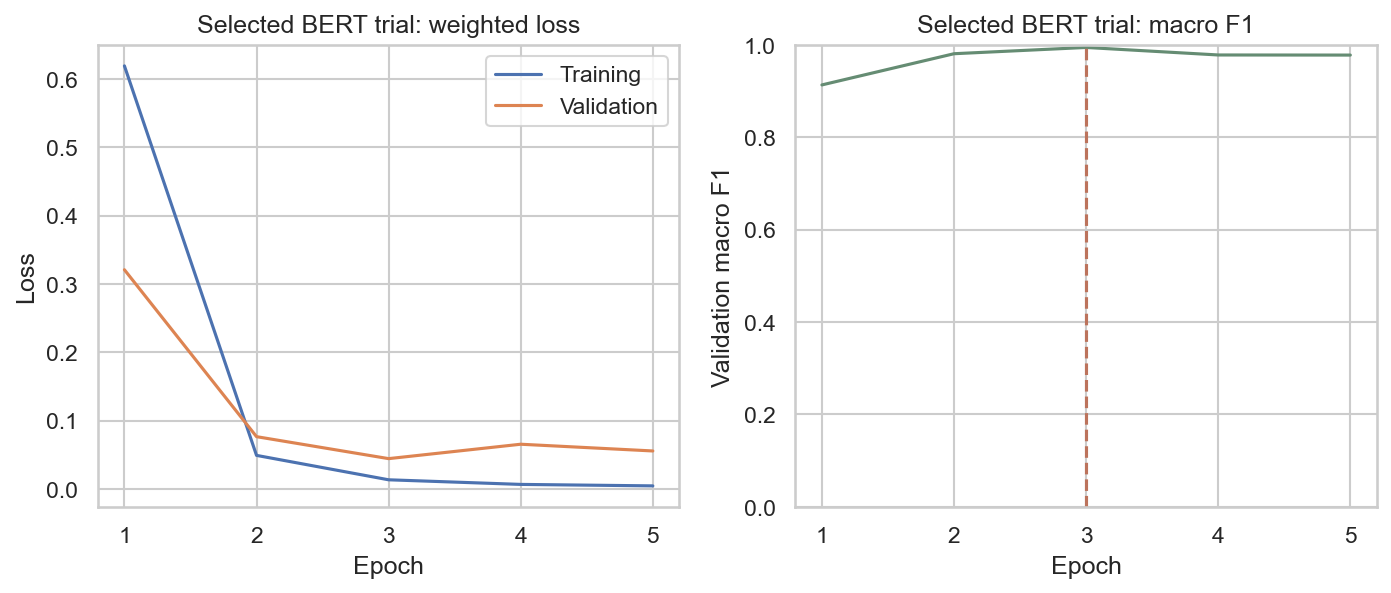

In [5]:
display(pd.read_csv(REPORTS / 'bert' / 'trial_comparison.csv'))
selection = bert['selection']
print('Selected trial:', selection['selected_trial'])
print('Selected before test:', selection['selected_at_utc'], bert['test_evaluation_started_at_utc'])
assert selection['test_used_for_selection'] is False
display(Image(filename=str(REPORTS / 'figures' / 'bert_learning_curves.png')))

## 5. Actual classifier comparison

The compact BERT did not beat the TextCNN on this source snapshot. All measured classifier results are retained; a larger/pretrained model is not assumed to be better.

,model,display_name,phase,validation_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_group_balanced_macro_f1,classical_benchmark
0,logistic_regression,Logistic Regression,2,0.835485,0.976608,0.981481,0.980676,0.979940,0.932692,False
1,linear_svm,Linear SVM,2,0.856522,0.956140,0.968354,0.963768,0.962192,0.964286,False
2,random_forest,Random Forest,2,0.867136,0.970760,0.977186,0.975845,0.975116,0.968761,True
3,text_cnn,PyTorch TextCNN,3,0.997238,0.985380,0.987597,0.987923,0.987595,0.985869,False
4,bert_mini,Fine-tuned BERT-mini,4,0.994410,0.953216,0.964294,0.959901,0.959712,0.912373,False


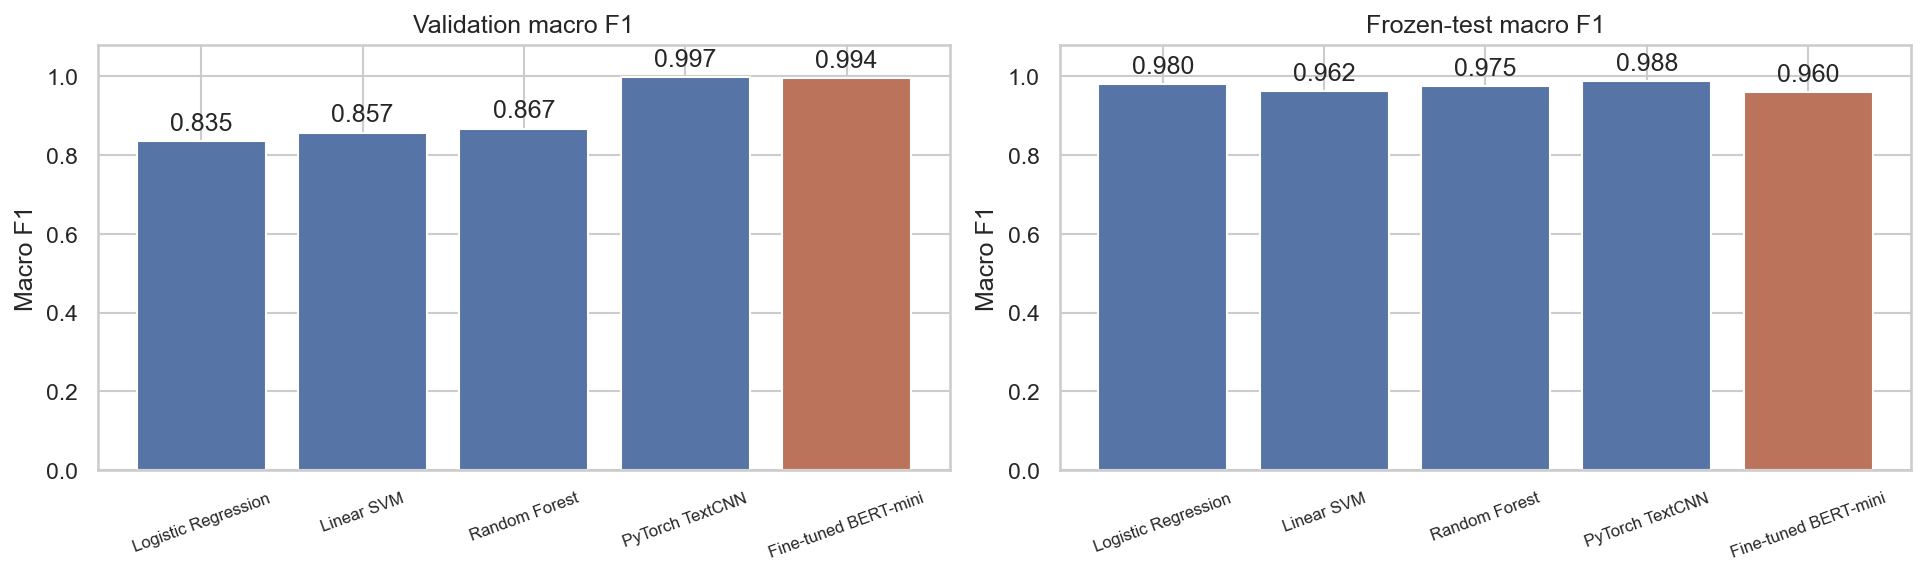

In [6]:
display(pd.read_csv(REPORTS / 'bert' / 'model_comparison.csv'))
display(Image(filename=str(REPORTS / 'figures' / 'classifier_comparison.png')))

,model,class_label,precision,recall,f1,support,groups
0,bert_mini,antibacterial,1.000000,0.855072,0.921875,69,5
1,bert_mini,anti_inflammatory_nsaid,1.000000,0.921875,0.959350,64,2
2,bert_mini,corticosteroid,0.853333,1.000000,0.920863,64,2
3,bert_mini,antifungal,0.932432,1.000000,0.965035,69,2
4,bert_mini,acid_reducer,1.000000,1.000000,1.000000,19,2
5,bert_mini,antihypertensive,1.000000,0.982456,0.991150,57,3


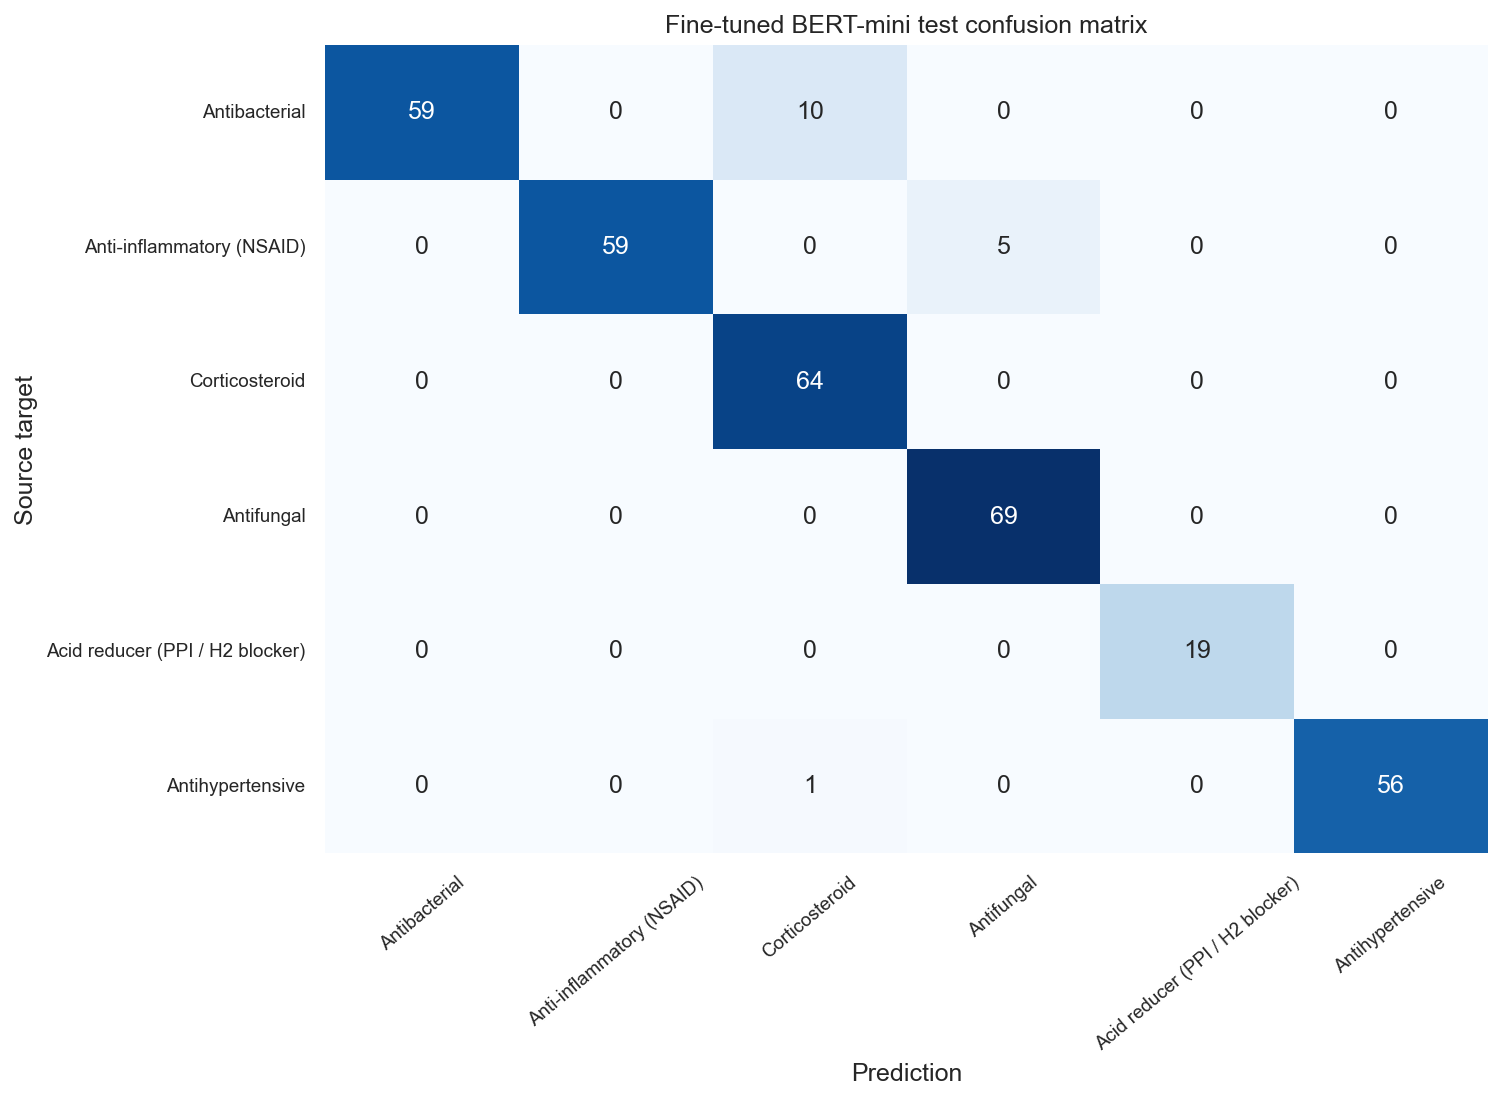

In [7]:
display(pd.read_csv(REPORTS / 'bert' / 'per_class_test_metrics.csv'))
display(Image(filename=str(REPORTS / 'figures' / 'bert_confusion_matrix.png')))

In [8]:
display(pd.Series(classify_bert_text(checkpoint, text)))

predicted_class                                                                                           acid_reducer
model                                                                                                        bert_mini
class_labels       [antibacterial, anti_inflammatory_nsaid, corticosteroid, antifungal, acid_reducer, antihypertens...
token_count                                                                                                        785
encoded_tokens                                                                                                     508
dtype: object

## 6. Local document-grounded retrieval and QA

A source-preserving chunker indexes the whole cleaned document. MiniLM embeddings are normalized and stored in a per-document FAISS index. Broad section questions can retrieve explicit source headings. Specific questions use answerability/null-margin and question-focus checks. The local instruction model's span is verified; unsupported generated text is not exposed. Output is a source quotation or the missing-answer fallback.

In [9]:
assistant = DocumentAssistant(ROOT, config)
index = assistant.index_document(text, 'real development esomeprazole leaflet')
print('Document ID:', index.metadata['document_id'])
print('FAISS chunks / embedding dimensions:', index.index.ntotal, index.vectors.shape[1])
display(pd.DataFrame(index.chunks)[['chunk_id', 'char_start', 'char_end', 'text']])
assert index.chunks[-1]['char_end'] == len(index.document)

Some weights of the model checkpoint at G:\Projects\Training-Final-Project\models\phase4\pretrained\qa were not used when initializing BertForQuestionAnswering: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForQuestionAnswering from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForQuestionAnswering from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Document ID: 6bf7825537c9facfb3f13e840006ae7d88b569711f156c01fc71762a03ceead3
FAISS chunks / embedding dimensions: 6 384


,chunk_id,char_start,char_end,text
0,chunk_0000,0,798,Indications And Usage\nUses • treats frequent heartburn (occurs 2 or more days a week) • not int...
1,chunk_0001,627,1446,use for more than 14 days unless directed by your doctor Repeated 14-Day Courses (if needed) • y...
2,chunk_0002,1263,2054,or shoulders; or lightheadedness • frequent chest pain These may be signs of a serious condition...
3,chunk_0003,1874,2687,"spreading to arms, neck or shoulders; or lightheadedness • frequent chest pain These may be sign..."
4,chunk_0004,2505,3315,need to take more than 1 course of treatment every 4 months • you get diarrhea • you develop a r...
5,chunk_0005,3134,3527,use and ask a doctor if • your heartburn continues or worsens • you need to take this product fo...


## 7. Source-quoted answer demonstration

The following question uses a real development leaflet. The returned quote and citation positions are checked against its canonical source text.

In [10]:
response = assistant.answer(index, 'How long can this product take for full effect?')
display(pd.Series({key: response.get(key) for key in ['question', 'answer', 'status', 'answer_mode', 'extracted_span', 'generation_verified']}))
display(pd.DataFrame(response['citations']))
assert response_supported(response, index.document)

question                               How long can this product take for full effect?
answer                 may take 1 to 4 days for full effect 14-Day Course of Treatment
status                                                                        answered
answer_mode                                                          verified_llm_span
extracted_span                                                             1 to 4 days
generation_verified                                                               True
dtype: object

,chunk_id,char_start,char_end,quote,passage
0,chunk_0000,366,429,may take 1 to 4 days for full effect 14-Day Course of Treatment,Indications And Usage\nUses • treats frequent heartburn (occurs 2 or more days a week) • not int...


In [11]:
missing = assistant.answer(index, 'What is the retail price of this product?')
print(missing['answer'])
assert missing['answer'] == MISSING_ANSWER and missing['citations'] == []

I cannot find that in the document.


In [12]:
restored = DocumentIndex.load(ROOT / 'data' / 'indexes' / index.metadata['document_id'])
assert restored.document == index.document
assert restored.index.ntotal == index.index.ntotal
print('Stored source text, vector index, offsets, and hashes loaded successfully.')

Stored source text, vector index, offsets, and hashes loaded successfully.


## 8. Source-linked MedQuAD-style QA cases

These are project-authored templates linked to real FDA source sections/spans, not the original MedQuAD dataset. The 48 cases include development, calibration, and evaluation. No medical reference facts are invented. The evaluation sources have different ingredient components from calibration/development.

In [13]:
cases = json.loads((ROOT / 'data' / 'evaluation' / 'phase4_qa_cases.json').read_text(encoding='utf-8'))
display(pd.DataFrame(cases['sources'])[['generic_names', 'partition', 'source_url']])
display(pd.DataFrame(cases['cases']).groupby(['partition', 'answerable']).size().rename('cases'))

,generic_names,partition,source_url
0,"[""ESOMEPRAZOLE MAGNESIUM DIHYDRATE""]",development,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=29eb7b87-59a4-4d27-ad53-789da7fec427
1,"[""ERYTHROMYCIN""]",calibration,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=9ac4dcd2-8cac-404d-b651-da74062d30ed
2,"[""ASPIRIN""]",evaluation,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=ac94cce3-9a39-41de-bb8b-10a5e5b8e83b
3,"[""DESOXIMETASONE""]",calibration,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=c84c7168-3d46-4e05-a25c-3d594ff94268
4,"[""NYSTATIN""]",evaluation,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=72dc2b60-29a4-48a8-848a-1a5086cfdd58
5,"[""FAMOTIDINE""]",calibration,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=ed32f72a-e220-440f-a74f-b754a313f004
6,"[""PINDOLOL""]",evaluation,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=8498aead-0aef-4cd8-a191-05cae57a55e5


partition    answerable
calibration  False          9
             True          11
development  False          3
             True           5
evaluation   False          9
             True          11
Name: cases, dtype: int64

## 9. Recorded QA evaluation and correction history

The initial policy quoted a strength description for one frequency question. A general temporal-answer check corrected the mismatch. The initial results are preserved. Updated scores are post-correction regression results on the same small case set, not a fresh clinical validation or untouched-test estimate.

,policy,reference_coverage,source_support
0,initial,0.909091,1.0
1,corrected,1.000000,1.0


partition                                                                                     evaluation
cases                                                                                                 20
source_documents                                                                                       3
answerable_cases                                                                                      11
missing_answer_cases                                                                                   9
answerability_accuracy                                                                               1.0
answer_precision                                                                                     1.0
answer_recall                                                                                        1.0
answerability_f1                                                                                     1.0
correct_fallback_rate                                  

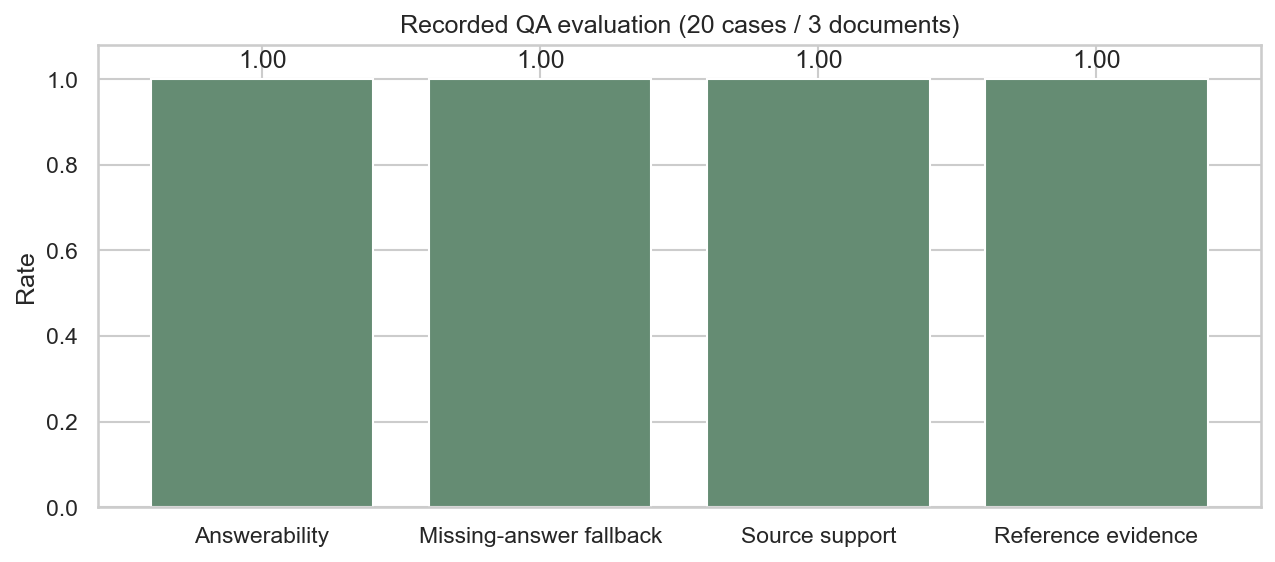

In [14]:
initial = json.loads((REPORTS / 'rag' / 'archive' / 'policy_v1' / 'evaluation_metrics.json').read_text(encoding='utf-8'))
metrics = json.loads((REPORTS / 'rag' / 'evaluation_metrics.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'policy': 'initial', 'reference_coverage': initial['positive_reference_evidence_coverage'], 'source_support': initial['source_support_rate']}, {'policy': 'corrected', 'reference_coverage': metrics['positive_reference_evidence_coverage'], 'source_support': metrics['source_support_rate']}]))
display(pd.Series(metrics))
display(Image(filename=str(REPORTS / 'figures' / 'qa_evaluation.png')))

In [15]:
display(pd.read_csv(REPORTS / 'rag' / 'evaluation_results.csv')[['question', 'answered', 'source_supported', 'reference_evidence_covered', 'answer_mode']])

,question,answered,source_supported,reference_evidence_covered,answer_mode
0,What does the document say about dosage and administration?,True,True,True,grounded_section_quote
1,What does the document say about when not to use this product?,True,True,True,grounded_section_quote
2,What does the document say about pregnancy or breast-feeding?,True,True,True,grounded_section_quote
3,What does the document say about warnings?,True,True,True,grounded_section_quote
4,What is the retail price stated in this document?,False,True,False,not_found
5,What is my prescribing doctor's telephone number?,False,True,False,not_found
6,What is my insurance policy number?,False,True,False,not_found
7,What does the document say about dosage and administration?,True,True,True,grounded_section_quote
8,What does the document say about contraindications?,True,True,True,grounded_section_quote
9,What does the document say about adverse reactions and side effects?,True,True,True,grounded_section_quote


## 10. Artifact verification and phase checkpoint

Checks cover immutable model revisions/assets, BERT selection/refit/metrics, source-linked case data, independent document indexes, exact citation offsets, missing-answer output, and preserved evaluation history. The benchmark is small and section-template-heavy; it does not establish universal medical reasoning accuracy or Arabic QA performance.

In [16]:
verification = json.loads((REPORTS / 'validation.json').read_text(encoding='utf-8'))
assert verification['all_passed']
print('Passed artifact checks:', len(verification['checks']))
display(pd.DataFrame(verification['checks'])[['name', 'passed']])

Passed artifact checks: 54


,name,passed
0,same_frozen_corpus_and_split,True
1,phase4_configuration_checksum,True
2,phase3_comparison_preserved,True
3,bert_pinned_revision,True
4,bert_asset_hashes,True
5,embedding_pinned_revision,True
6,embedding_asset_hashes,True
7,qa_pinned_revision,True
8,qa_asset_hashes,True
9,generation_pinned_revision,True


## Stop for Phase 4 review

Review `reports/phase_4_review.md`, the classifier results, model-size/context tradeoff, live QA examples, source citations, fallback behavior, and corrected-versus-original evaluation.

After review, Phase 5 will build FastAPI/Streamlit, deployment, and the capstone presentation.

Data provided by the U.S. Food and Drug Administration (https://open.fda.gov). deepset QA model attribution: https://huggingface.co/deepset/minilm-uncased-squad2 (CC BY 4.0). This product uses publicly available data from the U.S. National Library of Medicine (NLM), National Institutes of Health, Department of Health and Human Services; NLM is not responsible for the product and does not endorse or recommend this or any other product.